In [49]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import deque
import random

In [50]:
def is_grayscale(img):
    return len(img.shape) == 2

def apply_threshold(gray_img, threshold):
    binary_img = np.zeros_like(gray_img)
    binary_img[gray_img >= threshold] = 255
    return binary_img

def get_neighbors(row, col, rows, cols, connectivity=4):
    neighbors = []
    if connectivity == 4:
        potential_neighbors = [(row - 1, col), (row + 1, col), (row, col - 1), (row, col + 1)]
    elif connectivity == 8:
        potential_neighbors = [(row - 1, col - 1), (row - 1, col), (row - 1, col + 1),
                               (row, col - 1),                     (row, col + 1),
                               (row + 1, col - 1), (row + 1, col), (row + 1, col + 1)]
    else:
        raise ValueError("Connectivity must be 4 or 8")

    for nr, nc in potential_neighbors:
        if 0 <= nr < rows and 0 <= nc < cols:
            neighbors.append((nr, nc))
    return neighbors

def connected_components(binary_img, connectivity=4):

    rows, cols = binary_img.shape
    labeled_img = np.zeros((rows, cols), dtype=np.int32)
    label_map = {}
    next_label = 1


    for r in range(rows):
        for c in range(cols):
            if binary_img[r, c] == 255 and labeled_img[r, c] == 0:
                neighbors = get_neighbors(r, c, rows, cols, connectivity)
                neighbor_labels = [labeled_img[nr, nc] for nr, nc in neighbors if labeled_img[nr, nc] > 0]

                if not neighbor_labels:
                    labeled_img[r, c] = next_label
                    label_map[next_label] = next_label
                    next_label += 1
                else:
                    min_label = min(neighbor_labels)
                    labeled_img[r, c] = min_label
                    for nl in neighbor_labels:
                        if nl != min_label:
                            if nl in label_map:
                                label_map[nl] = min(label_map[nl], min_label)
                            else:
                                label_map[nl] = min_label
                            if min_label in label_map:
                                label_map[min_label] = min(label_map[min_label], min_label)
                            else:
                                label_map[min_label] = min_label


    for r in range(rows):
        for c in range(cols):
            if labeled_img[r, c] > 0:
                current_label = labeled_img[r, c]
                while current_label != label_map.get(current_label, current_label):
                    label_map[current_label] = label_map.get(label_map[current_label], label_map[current_label])
                    current_label = label_map[current_label]
                labeled_img[r, c] = current_label


    unique_labels = np.unique(labeled_img[labeled_img > 0])
    new_labels = {label: i for i, label in enumerate(unique_labels, start=1)}
    for r in range(rows):
        for c in range(cols):
            if labeled_img[r, c] > 0:
                labeled_img[r, c] = new_labels[labeled_img[r, c]]

    return labeled_img

def connected_components_thresholding(gray_img, thresholds, connectivity=4):

    if not is_grayscale(gray_img):
        return np.zeros_like(gray_img)

    rows, cols = gray_img.shape
    segmented_img = np.zeros((rows, cols), dtype=np.int32)
    global_label = 1

    sorted_thresholds = sorted(thresholds)
    for i in range(len(sorted_thresholds)):
        lower_thresh = sorted_thresholds[i]
        upper_thresh = 255 if i == len(sorted_thresholds) - 1 else sorted_thresholds[i + 1]

        binary_mask = (gray_img >= lower_thresh) & (gray_img < upper_thresh)
        binary_img = np.zeros_like(gray_img)
        binary_img[binary_mask] = 255

        labeled_component_img = connected_components(binary_img, connectivity)

        unique_labels = np.unique(labeled_component_img[labeled_component_img > 0])
        for local_label in unique_labels:
            mask = (labeled_component_img == local_label) & (segmented_img == 0)
            segmented_img[mask] = global_label
            global_label += 1

    return segmented_img

def color_segmented_image_mean(gray_img, segmented_img):
    rows, cols = gray_img.shape
    colored_img_gray = np.zeros((rows, cols), dtype=np.uint8)
    unique_labels = np.unique(segmented_img[segmented_img > 0])

    for label in unique_labels:
        mask = segmented_img == label
        mean_val = np.mean(gray_img[mask])
        colored_img_gray[mask] = mean_val

    # Convert to RGB grayscale
    colored_img_rgb = cv2.cvtColor(colored_img_gray, cv2.COLOR_GRAY2BGR)

    return colored_img_rgb


def color_segmented_image_random(segmented_img):

    rows, cols = segmented_img.shape
    colored_img = np.zeros((rows, cols, 3), dtype=np.uint8)
    unique_labels = np.unique(segmented_img[segmented_img > 0])
    label_colors = {label: (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255)) for label in unique_labels}

    for label in unique_labels:
        mask = segmented_img == label
        colored_img[mask] = label_colors[label]

    return colored_img


In [51]:
image_urls = ["/content/example1 (1).png",
               "/content/example2 (1).jpeg",
                "/content/example3 (1).jpeg"]
images=[]
for url in image_urls:
    try:
        img = cv2.imread(url, cv2.IMREAD_GRAYSCALE)

        if img is None:
            raise Exception(f"Failed to load image from {url}")
        images.append(img)
    except Exception as e:
        print(f"Error loading image from {url}: {e}")
        images.append(np.zeros((200, 200), dtype=np.uint8))



In [52]:

all_results = []

threshold_sets = [
    [50, 100, 150, 200],
    [80, 160],
    [120],
    [30, 90, 150],
    [70, 140, 210],
    [110, 180]

]

for img_idx, gray_img in enumerate(images):
    img_results = []
    for thresh_set in threshold_sets:
        segmented_img = connected_components_thresholding(gray_img.copy(), thresh_set, connectivity=8)
        colored_mean = color_segmented_image_mean(gray_img.copy(), segmented_img.copy())
        colored_random = color_segmented_image_random(segmented_img.copy())

        img_results.append({
            "thresholds": thresh_set,
            "segmented": segmented_img,
            "colored_mean": colored_mean,
            "colored_random": colored_random
        })

    all_results.append(img_results)

Results for Image 1


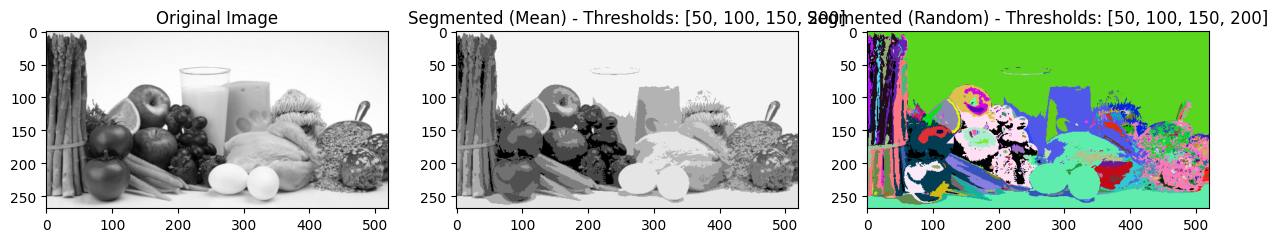

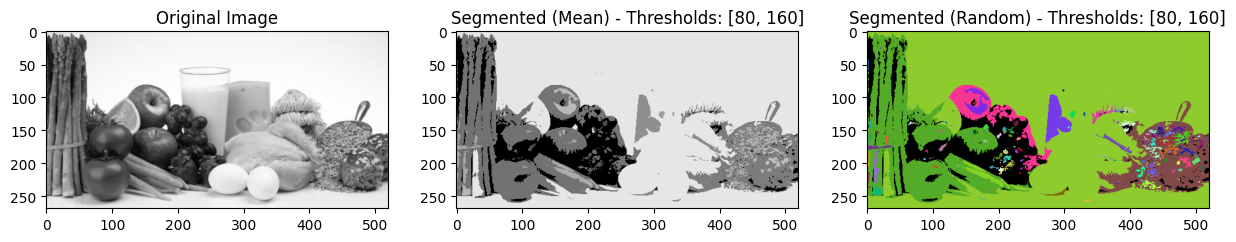

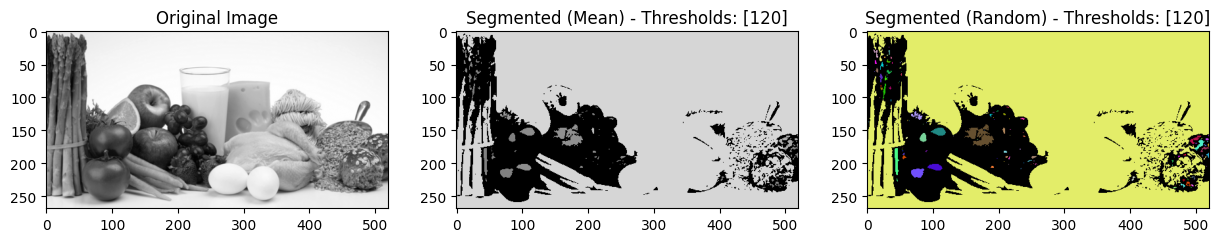

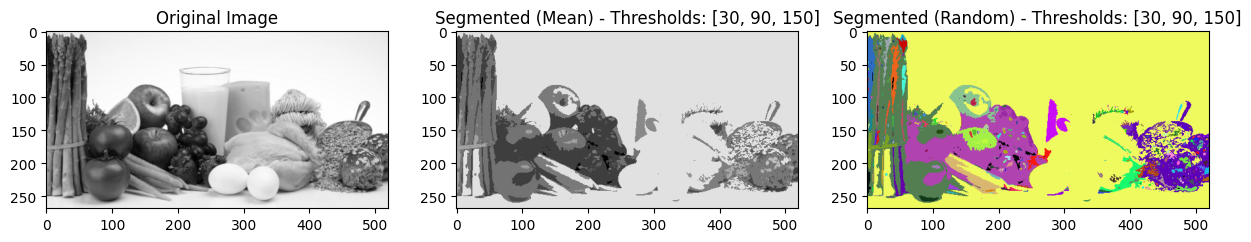

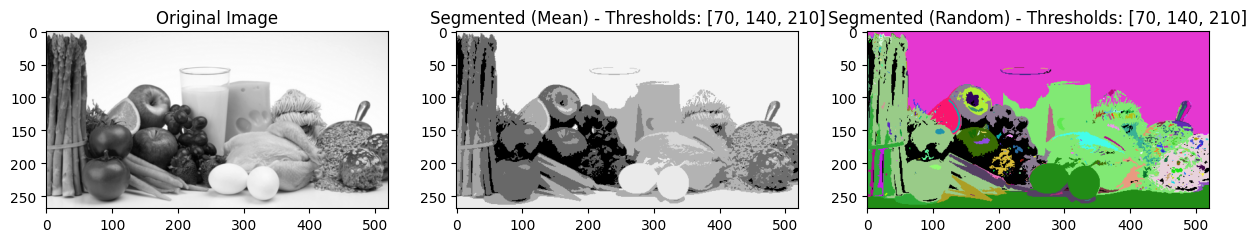

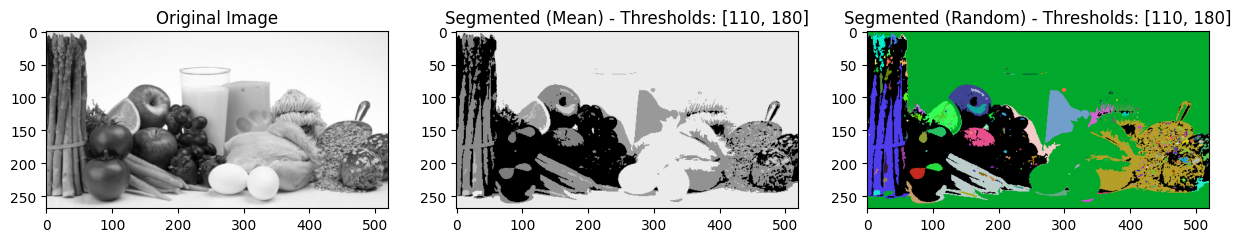

In [57]:


print("Results for Image 1")
for i, result in enumerate(all_results[0]):
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(images[0], cmap='gray')
    plt.title("Original Image")

    plt.subplot(1, 3, 2)
    plt.imshow(result["colored_mean"], cmap='gray')
    plt.title(f"Segmented (Mean) - Thresholds: {result['thresholds']}")

    plt.subplot(1, 3, 3)
    plt.imshow(result["colored_random"])
    plt.title(f"Segmented (Random) - Thresholds: {result['thresholds']}")

    plt.show()


Results for Image 2


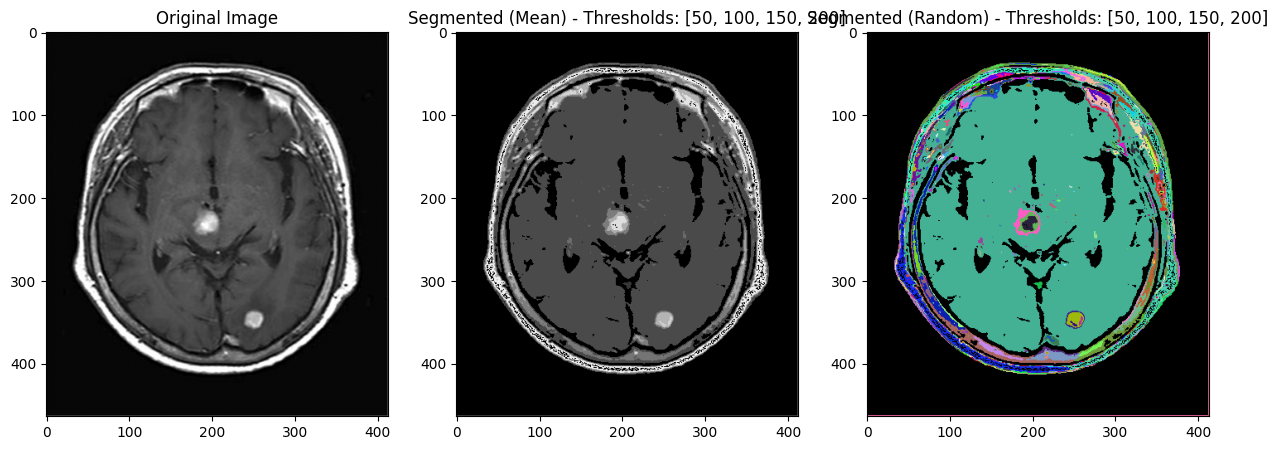

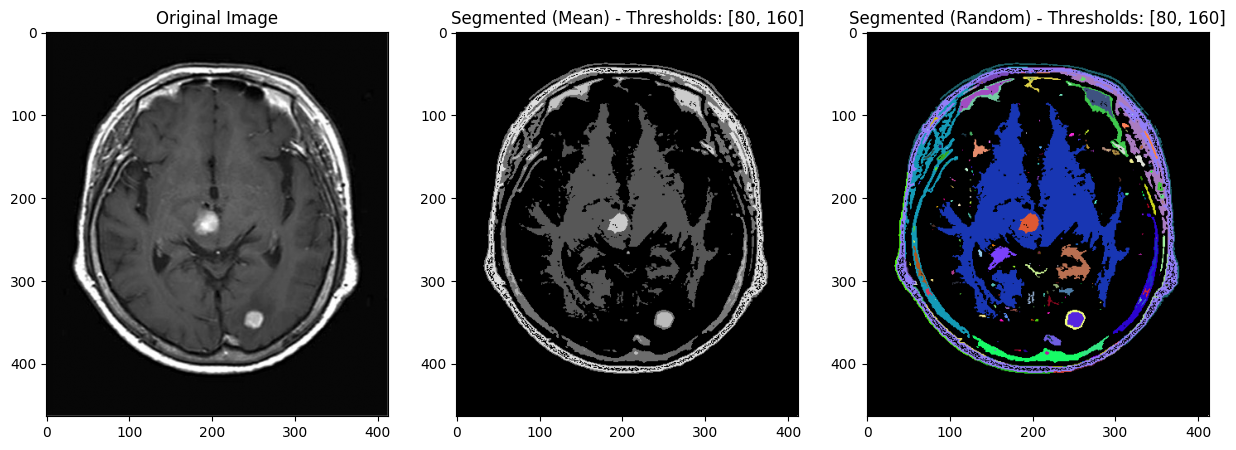

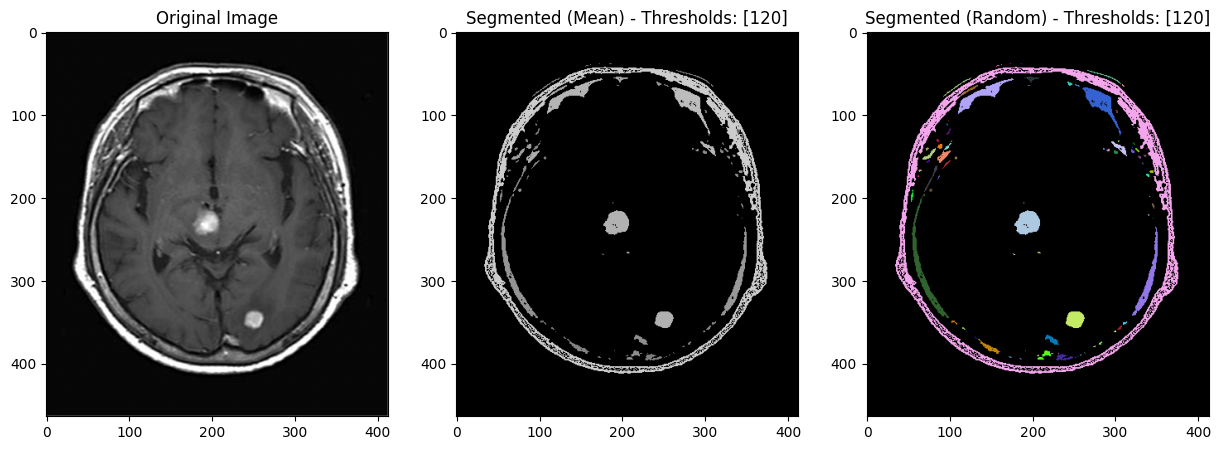

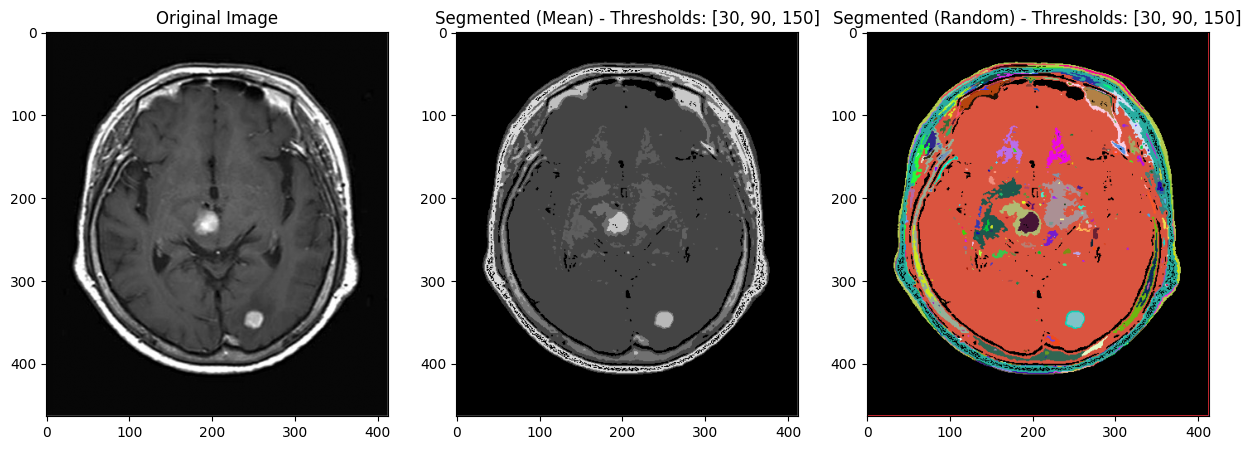

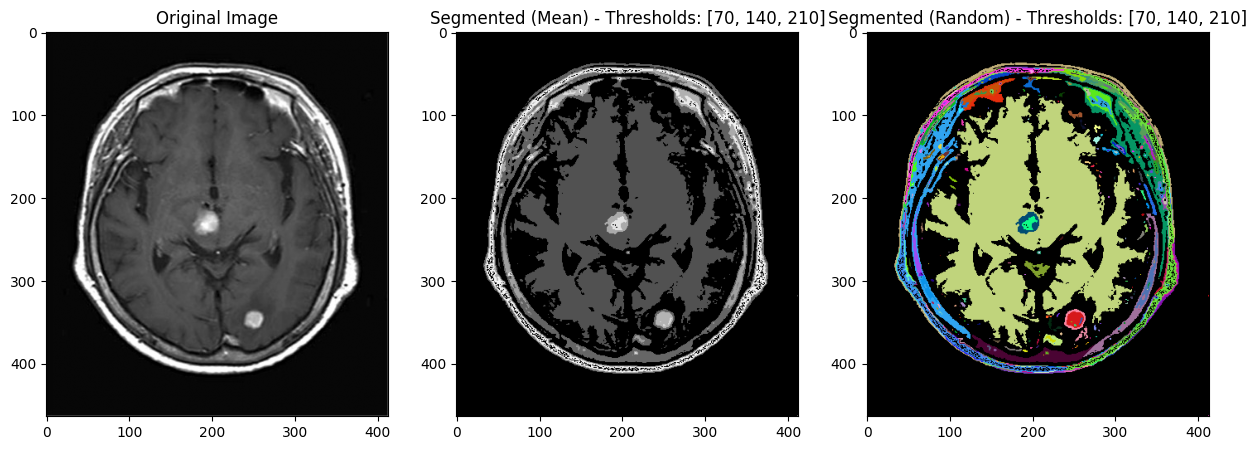

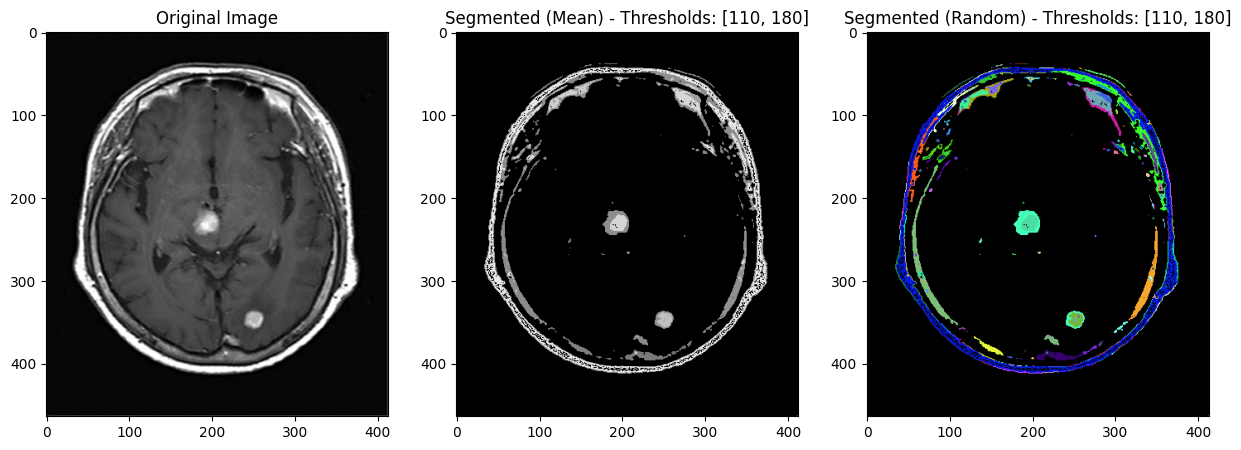

In [54]:


print("Results for Image 2")
for i, result in enumerate(all_results[1]):
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(images[1], cmap='gray')
    plt.title("Original Image")

    plt.subplot(1, 3, 2)
    plt.imshow(result["colored_mean"], cmap='gray')
    plt.title(f"Segmented (Mean) - Thresholds: {result['thresholds']}")

    plt.subplot(1, 3, 3)
    plt.imshow(result["colored_random"])
    plt.title(f"Segmented (Random) - Thresholds: {result['thresholds']}")

    plt.show()

Results for Image 3


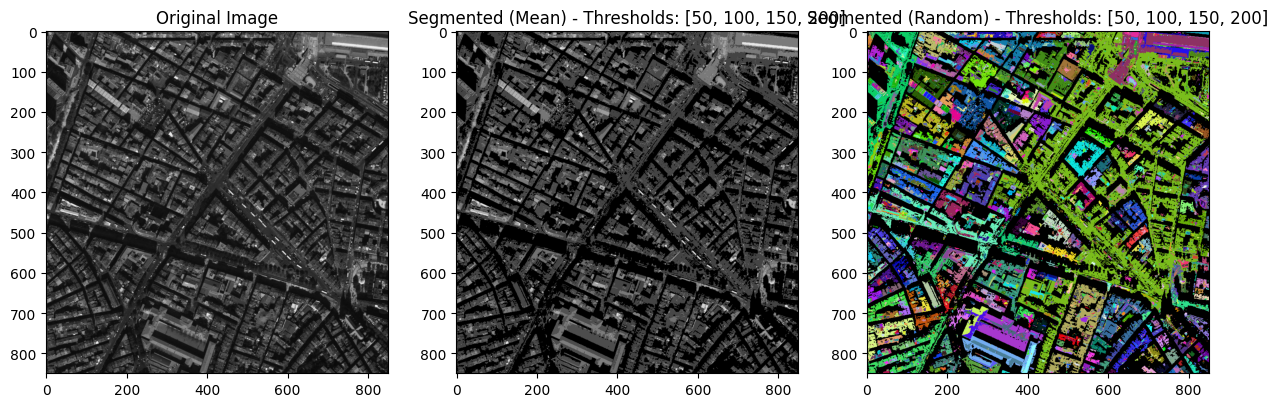

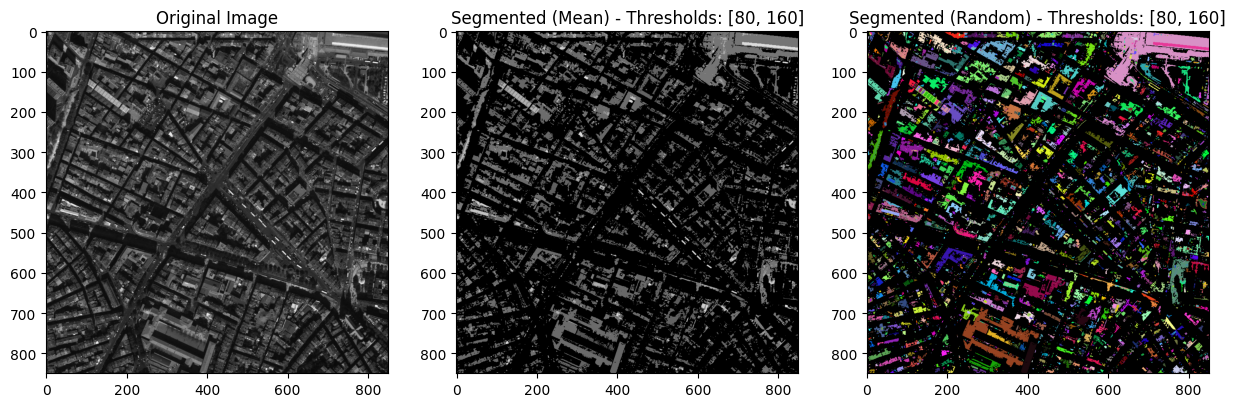

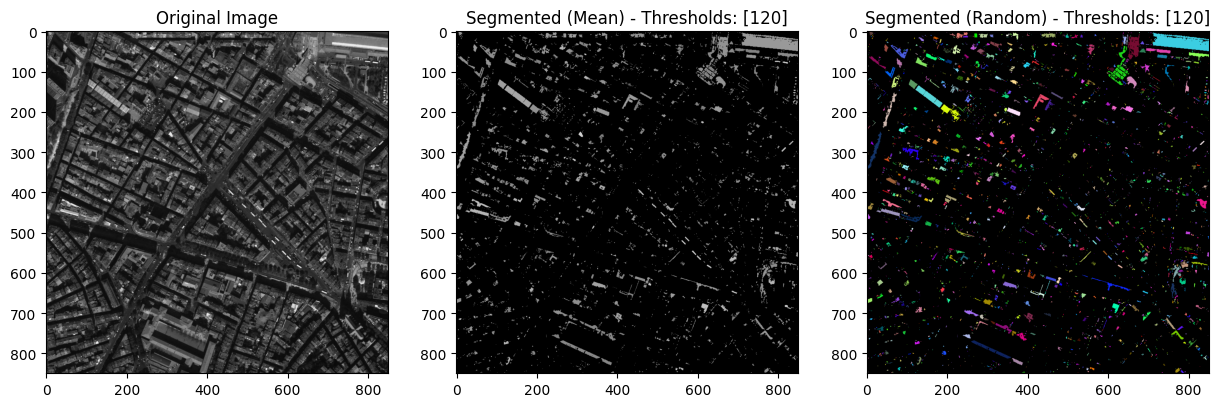

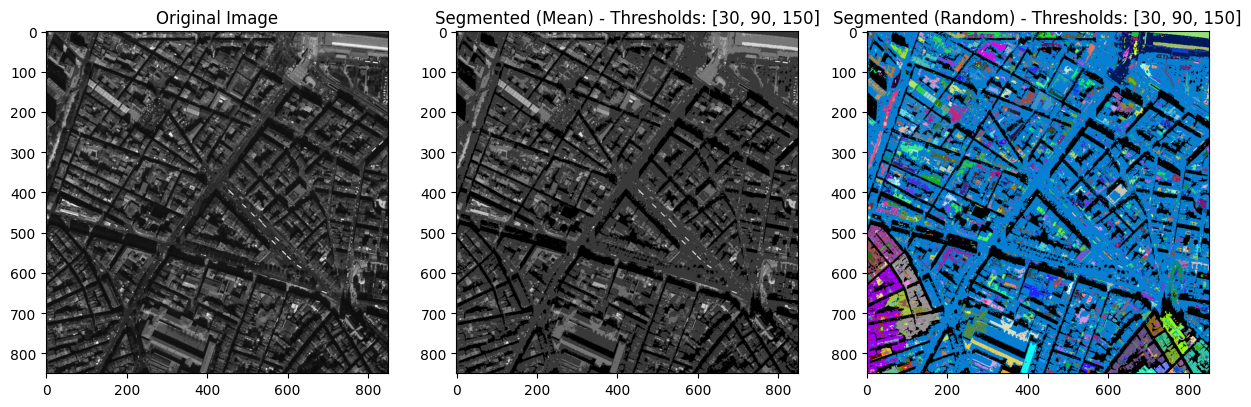

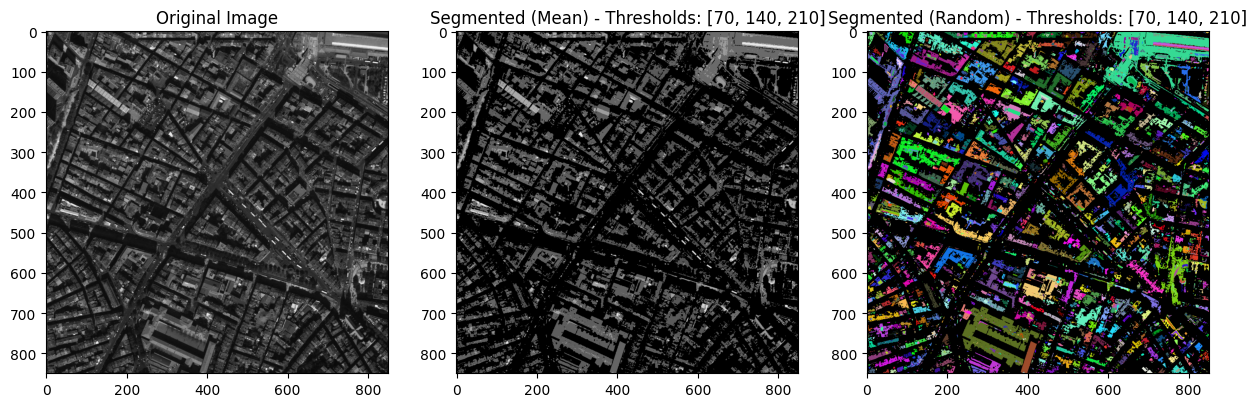

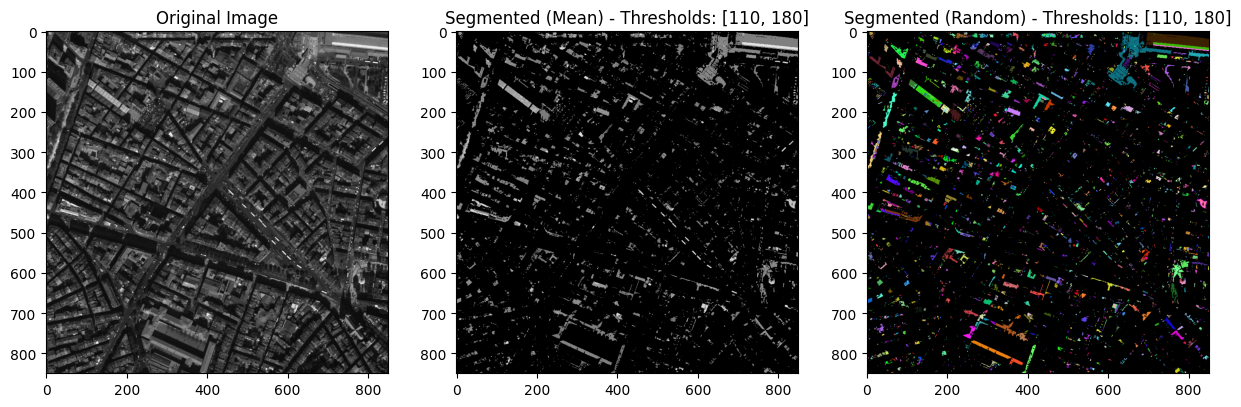

In [55]:

print("Results for Image 3")
for i, result in enumerate(all_results[2]):
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(images[2], cmap='gray')
    plt.title("Original Image")

    plt.subplot(1, 3, 2)
    plt.imshow(result["colored_mean"], cmap='gray')
    plt.title(f"Segmented (Mean) - Thresholds: {result['thresholds']}")

    plt.subplot(1, 3, 3)
    plt.imshow(result["colored_random"])
    plt.title(f"Segmented (Random) - Thresholds: {result['thresholds']}")

    plt.show()